# 01 — Qualité des données et exploration de l’IPCH

Objectif : vérifier les six séries de la zone euro (global et cinq composantes), puis examiner leur comportement avant de construire les modèles désagrégés.

Les données brutes et préparées restent inchangées. Aucune imputation et aucun retrait de valeurs extrêmes. Les contrôles structurels portent sur toute la couverture ; les graphiques et statistiques économiques excluent les 24 mois réservés au test final. Ce notebook ne valide pas encore la reconstruction des agrégats.

Exécuter les cellules dans l’ordre avec l’environnement `.venv` du projet.

In [3]:
pip install httpx

  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
Using cached httpx-0.28.1-py3-none-any.whl (73 kB)
Using cached httpcore-1.0.9-py3-none-any.whl (78 kB)
Using cached h11-0.16.0-py3-none-any.whl (37 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [httpx]32m2/3 [httpx]re]

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import hashlib
import json
import sys

# Fonctionne depuis la racine du dépôt ou son dossier not.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "config.py").is_file() and (p / "prepare_panel.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Placer ce notebook dans notebooks du projet cacib-hicp.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if hasattr(value, "to_string") else value)
import config
from prepare_panel import select_manifest

COMPONENTS = {
    "TOTAL": "IPCH global",
    "SERV": "Services",
    "IGD_NNRG": "Biens industriels hors énergie",
    "NRG": "Énergie",
    "FOOD_P": "Alimentation transformée, alcool et tabac",
    "FOOD_NP": "Alimentation non transformée",
}
END = pd.Period(config.END_PERIOD, freq="M")
TEST_START = END - 23
EDA_END = TEST_START - 1
print("Python :", sys.executable)
print("Exploration économique jusqu’à :", EDA_END)
print("Test final réservé :", TEST_START, "à", END)

Python : /Library/Frameworks/Python.framework/Versions/3.11/bin/python3.11
Exploration économique jusqu’à : 2024-09
Test final réservé : 2024-10 à 2026-09


## 1. Charger une collecte préparée et auditée

In [3]:
pip install pyarrow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.7/38.7 MB 9.1 MB/s  0:00:04m0:00:0100:01

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
manifest_path, manifest = select_manifest()
PANEL = config.PROCESSED_DATA_DIR / "panel" / manifest["collection_id"]
audit_path = PANEL / "audit.json"
if not (PANEL / "_SUCCESS").is_file():
    raise RuntimeError("Exécuter prepare_panel.py avant ce notebook.")
audit = json.loads(audit_path.read_text(encoding="utf-8"))
assert audit["integrity_status"] == "passed", "Le panel ne passe pas les contrôles bloquants."
source = PANEL / "indices" / f"{config.EURO_AREA}.parquet"
raw = pd.read_parquet(source)
data = raw.loc[
    raw["geo"].eq(config.EURO_AREA)
    & raw["unit"].eq(config.INDEX_UNIT)
    & raw["freq"].eq(config.FREQUENCY)
    & raw["coicop18"].isin(COMPONENTS)
].copy()
data["month"] = pd.PeriodIndex(data["time"], freq="M")
expected = pd.period_range(config.START_PERIOD, config.END_PERIOD, freq="M")
print("Collecte :", manifest["collection_id"])
print("Source :", source.relative_to(ROOT))

Collecte : 20261027T025449_589983Z
Source : data/processed/panel/20261027T025449_589983Z/indices/EA.parquet


## 2. Audit des six séries

Une série est exploitable ici si chaque mois apparaît exactement une fois avec une valeur finie et strictement positive. Les indicateurs de publication sont conservés et affichés ; leur présence ne signifie pas automatiquement qu’une observation est inutilisable.

In [3]:
rows = []
for component, label in COMPONENTS.items():
    part = data.loc[data["coicop18"].eq(component)].sort_values("month")
    values = part["value"].to_numpy(dtype=float, na_value=np.nan)
    months = pd.PeriodIndex(part["month"], freq="M")
    duplicate_count = int(months.duplicated().sum())
    absent_count = len(expected.difference(months))
    outside_count = len(months.difference(expected))
    missing_count = int(np.isnan(values).sum())
    infinite_count = int(np.isinf(values).sum())
    nonpositive_count = int((values <= 0).sum())
    passed = (len(part) == len(expected) and not any([
        duplicate_count, absent_count, outside_count, missing_count,
        infinite_count, nonpositive_count]))
    rows.append(dict(code=component, composante=label, observations=len(part),
                     mois_absents=absent_count, doublons=duplicate_count,
                     hors_periode=outside_count, valeurs_manquantes=missing_count,
                     valeurs_infinies=infinite_count, valeurs_non_positives=nonpositive_count,
                     exploitable=passed))
quality = pd.DataFrame(rows).set_index("code")
display(quality)
flags = (data.assign(status=data["status"].fillna("").replace("", "sans indicateur"))
         .groupby(["coicop18", "status"]).size().rename("observations").reset_index())
display(flags)
levels = (data.pivot(index="month", columns="coicop18", values="value")
          .reindex(index=expected, columns=list(COMPONENTS)).astype(float))
# Une histoire commune plus courte est acceptable, sans imputation.
# Les trous à l’intérieur de cette histoire restent bloquants.
if quality[["doublons", "hors_periode", "valeurs_infinies", "valeurs_non_positives"]].to_numpy().any():
    raise ValueError("Anomalies structurelles : examiner les séries avant de poursuivre.")
if levels.notna().sum().eq(0).any():
    raise ValueError("Au moins une série n’a aucune observation.")
COMMON_START = max(levels[c].first_valid_index() for c in COMPONENTS)
common = levels.loc[COMMON_START:]
if common.isna().any().any():
    raise ValueError("Des trous subsistent dans la période commune : investigation requise.")
print("Période commune complète :", COMMON_START, "à", END)
print("Les débuts manquants restent conservés dans les données ; aucune imputation.")

,composante,observations,mois_absents,doublons,hors_periode,valeurs_manquantes,valeurs_infinies,valeurs_non_positives,exploitable
code,,,,,,,,,
TOTAL,IPCH global,369,0,0,0,0,0,0,True
SERV,Services,369,0,0,0,47,0,0,False
IGD_NNRG,Biens industriels hors énergie,369,0,0,0,47,0,0,False
NRG,Énergie,369,0,0,0,0,0,0,True
FOOD_P,"Alimentation transformée, alcool et tabac",369,0,0,0,0,0,0,True
FOOD_NP,Alimentation non transformée,369,0,0,0,0,0,0,True


,coicop18,status,observations
0,FOOD_NP,b,1
1,FOOD_NP,d,252
2,FOOD_NP,sans indicateur,116
3,FOOD_P,b,1
4,FOOD_P,d,252
5,FOOD_P,sans indicateur,116
6,IGD_NNRG,b,1
7,IGD_NNRG,d,205
8,IGD_NNRG,sans indicateur,163
9,NRG,b,1


Période commune complète : 1999-12 à 2026-09
Les débuts manquants restent conservés dans les données ; aucune imputation.


## 3. Indices et variations

Inflation annuelle : `100 × (I[t] / I[t−12] − 1)`. Variation mensuelle : `100 × (I[t] / I[t−1] − 1)`.

Les premières variations sans base historique restent manquantes. Les variations mensuelles ne sont pas désaisonnalisées. Les grands mouvements sont des éléments à expliquer, pas des erreurs à supprimer.

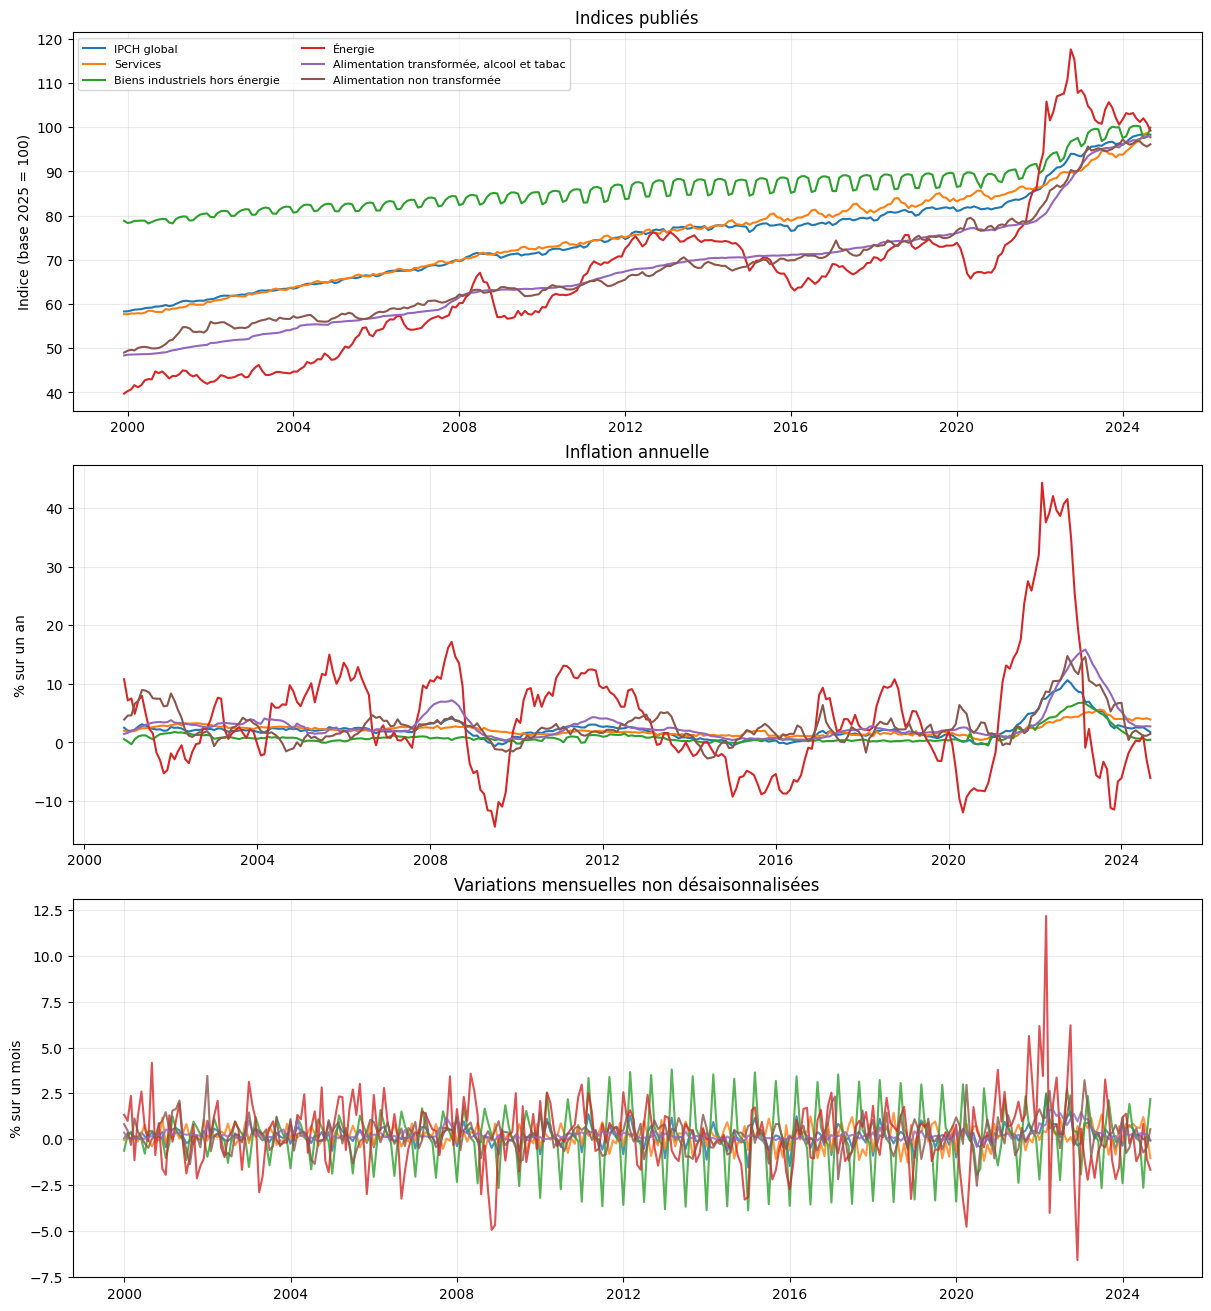

,count,mean,std,min,25%,50%,75%,max
coicop18,,,,,,,,
IPCH global,286.0,2.145,1.866,-0.658,1.174,1.982,2.484,10.614
Services,286.0,2.127,0.976,0.405,1.378,1.940,2.590,5.604
Biens industriels hors énergie,286.0,0.985,1.314,-0.536,0.309,0.668,1.029,6.776
Énergie,286.0,4.208,10.005,-14.401,-1.947,2.463,9.228,44.319
"Alimentation transformée, alcool et tabac",286.0,2.959,2.759,0.332,1.549,2.224,3.311,15.838
Alimentation non transformée,286.0,2.835,2.969,-2.749,1.144,2.183,3.688,14.738


In [4]:
explore = common.loc[:EDA_END].copy()
yoy = 100 * (explore / explore.shift(12) - 1)
mom = 100 * (explore / explore.shift(1) - 1)
fig, axes = plt.subplots(3, 1, figsize=(12, 13), constrained_layout=True)
for code_, label in COMPONENTS.items():
    dates = explore.index.to_timestamp()
    axes[0].plot(dates, explore[code_], label=label)
    axes[1].plot(dates, yoy[code_], label=label)
    axes[2].plot(dates, mom[code_], label=label, alpha=0.8)
for ax, title, unit in zip(axes,
    ["Indices publiés", "Inflation annuelle", "Variations mensuelles non désaisonnalisées"],
    ["Indice (base 2025 = 100)", "% sur un an", "% sur un mois"]):
    ax.set_title(title)
    ax.set_ylabel(unit)
    ax.grid(alpha=0.25)
axes[0].legend(loc="upper left", fontsize=8, ncol=2)
plt.show()
display(yoy.describe().T.rename(index=COMPONENTS).round(3))

## 4. Saisonnalité descriptive et mouvements extrêmes

Les moyennes par mois donnent une première description ; elles ne constituent pas un test formel de stabilité saisonnière. La sélection des modèles devra rester fondée sur la validation chronologique.

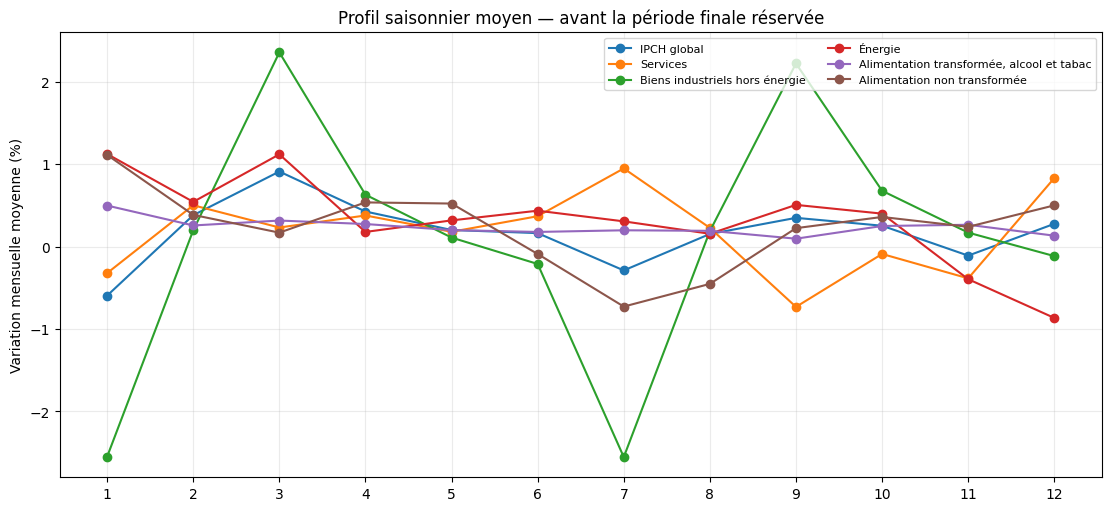

,code,mois,variation_mensuelle_pct
0,TOTAL,2022-03,2.431156
1,TOTAL,2015-01,-1.548387
2,TOTAL,2022-10,1.479002
3,TOTAL,2016-01,-1.467370
4,TOTAL,2011-03,1.354865
5,SERV,2018-07,1.439284
6,SERV,2023-07,1.349904
7,SERV,2018-11,-1.280657
8,SERV,2016-07,1.234414
9,SERV,2018-09,-1.226190


In [5]:
seasonality = mom.groupby(mom.index.month).mean()
seasonality.index.name = "mois"
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
for code_, label in COMPONENTS.items():
    ax.plot(seasonality.index, seasonality[code_], marker="o", label=label)
ax.set_xticks(range(1, 13))
ax.set_ylabel("Variation mensuelle moyenne (%)")
ax.set_title("Profil saisonnier moyen — avant la période finale réservée")
ax.grid(alpha=0.25)
ax.legend(fontsize=8, ncol=2)
plt.show()
extremes = []
for component in COMPONENTS:
    ranked = mom[component].dropna().abs().nlargest(5)
    for month in ranked.index:
        extremes.append({"code": component, "mois": str(month),
                         "variation_mensuelle_pct": float(mom.loc[month, component])})
display(pd.DataFrame(extremes))

## 5. Poids des cinq composantes

Les poids sont exprimés sur 1 000. Cette vérification porte sur leur présence et leur somme annuelle. Elle ne prouve pas que l’indice global se reconstruit par une moyenne des indices ou des taux : la reconstruction chaînée sera une étape séparée.

Pour éviter de guider les choix à partir du test final, les poids affichés ici s’arrêtent à l’année précédant son début.

In [6]:
weights_source = PANEL / "item_weights" / f"{config.EURO_AREA}.parquet"
weights_raw = pd.read_parquet(weights_source)
branches = [c for c in COMPONENTS if c != "TOTAL"]
selected_weights = weights_raw.loc[
    weights_raw["coicop18"].isin(["TOTAL", *branches])
    & weights_raw["year"].lt(TEST_START.year)
].copy()
if selected_weights.duplicated(["year", "coicop18"]).any():
    raise ValueError("Doublons dans les poids : vérifier les dimensions sélectionnées.")
weights = selected_weights.pivot(index="year", columns="coicop18", values="value").astype(float)
weight_check = pd.DataFrame(index=weights.index)
weight_check["composantes_disponibles"] = weights.reindex(columns=branches).notna().sum(axis=1)
weight_check["somme_cinq_composantes"] = weights.reindex(columns=branches).sum(axis=1, min_count=5)
weight_check["poids_total"] = weights["TOTAL"]
weight_check["ecart_au_total"] = weight_check["somme_cinq_composantes"] - weight_check["poids_total"]
weight_check["negatif"] = (weights.reindex(columns=branches) < 0).any(axis=1)
weight_check["a_examiner"] = (
    weight_check["composantes_disponibles"].ne(5)
    | weight_check["poids_total"].isna()
    | weight_check["ecart_au_total"].abs().gt(0.2)
    | weight_check["poids_total"].sub(1000).abs().gt(0.2)
    | weight_check["negatif"])
display(weight_check)
print("Années de poids à examiner :", int(weight_check["a_examiner"].sum()))

,composantes_disponibles,somme_cinq_composantes,poids_total,ecart_au_total,negatif,a_examiner
year,,,,,,
1996,3,NaN,1000.0,NaN,False,True
1997,3,NaN,1000.0,NaN,False,True
1998,3,NaN,1000.0,NaN,False,True
1999,3,NaN,1000.0,NaN,False,True
2000,3,NaN,1000.0,NaN,False,True
2001,5,999.99,1000.0,-1.000000e-02,False,False
2002,5,999.99,1000.0,-1.000000e-02,False,False
2003,5,1000.00,1000.0,1.136868e-13,False,False
2004,5,1000.01,1000.0,1.000000e-02,False,False


Années de poids à examiner : 5


## 6. Conclusion et suite

À commenter après exécution :

- Les six séries passent-elles les contrôles ? Quels indicateurs de publication apparaissent ?
- Quelles composantes présentent les variations mensuelles et annuelles les plus fortes ?
- Quels profils saisonniers ressortent ? Sont-ils économiquement plausibles ?
- Les cinq poids sont-ils disponibles et leur somme cohérente ?

**Prochaine étape :** vérifier la reconstruction chaînée de l’IPCH avec les cinq composantes et les poids annuels, puis étendre les backtests. Ne pas utiliser la somme pondérée des taux annuels comme substitut automatique au chaînage.

**Limites :** millésime récent des données, absence de vintages historiques et de calendrier de publication simulé. Les poids futurs ne doivent pas être supposés connus à une origine historique.

In [7]:
# Petit compte rendu affiché, sans modifier les données sources.
summary = {
    "collection_id": manifest["collection_id"],
    "indices_sha256": hashlib.sha256(source.read_bytes()).hexdigest(),
    "poids_sha256": hashlib.sha256(weights_source.read_bytes()).hexdigest(),
    "six_series_completes_depuis_1996": bool(quality["exploitable"].all()),
    "debut_commun_sans_trous": str(COMMON_START),
    "fin_exploration": str(EDA_END),
    "debut_test_reserve": str(TEST_START),
    "annees_poids_a_examiner": int(weight_check["a_examiner"].sum()),
    "imputation": False,
    "reconstruction_agregat_validee": False,
}
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "collection_id": "20261027T025449_589983Z",
  "indices_sha256": "e600f9561cb8bf006ee5a76aa06a641eeb3bc6c70942518737b5343bf238abcb",
  "poids_sha256": "f2843a903b4436469e2cb614fef0128973100deaacc927002316c6c975e57d19",
  "six_series_completes_depuis_1996": false,
  "debut_commun_sans_trous": "1999-12",
  "fin_exploration": "2024-09",
  "debut_test_reserve": "2024-10",
  "annees_poids_a_examiner": 5,
  "imputation": false,
  "reconstruction_agregat_validee": false
}
